# Querying NWIS

`NWIS` queries the USGS Water Data API. It sends the key in `USGS_API_KEY`, when set, in
the `X-Api-Key` header. This notebook asks for the monitoring locations in a box around
Washington, DC, streams the pages as they arrive, collects a `QueryResult`, narrows the
query with a CQL2 filter, and fetches daily discharge split by year. `to_arrow()` turns
each result into a table for geopandas or polars, which needs the `arrow` extra.

In [1]:
from water_ogcapi import NWIS

DC = (-77.12, 38.80, -76.91, 38.99)
nwis = NWIS()

## Stream pages

`iter_pages()` yields one `Page` per response and follows each page's `next` link. A
`limit` of 200 shows the paging; the default is 10,000 features a page. NWIS reports no
`numberMatched`, so the total is known only once the last page arrives.

In [2]:
for page in nwis.iter_pages("monitoring-locations", bbox=DC, params={"limit": "200"}):
    print(page.status, page.feature_count, page.number_matched)

200 200 None


200 112 None


## Collect a result

`collect()` gathers every page into one FeatureCollection and records how the traversal
went: the checks that passed and the CRS the server named.

In [3]:
sites = nwis.collect("monitoring-locations", bbox=DC)
print(len(sites.geojson["features"]), "features in", sites.pagination.page_count, "page(s)")
print(sites.pagination.completeness, sites.pagination.checks)
print(sites.crs.effective, sites.crs.source)

312 features in 1 page(s)
complete ('end_of_links', 'unique_ids')
http://www.opengis.net/def/crs/OGC/1.3/CRS84 content_crs


## Filter with CQL2

A CQL2-Text `filter` combines with the bounding box. Only the stream sites:

In [4]:
streams = nwis.collect("monitoring-locations", bbox=DC, filter="site_type_code = 'ST'")
for feature in streams.geojson["features"][:10]:
    print(feature["id"], feature["properties"]["monitoring_location_name"])

USEPA-385353076573301 DC90S001
USGS-01646550 LITTLE FALLS BRANCH NEAR BETHESDA, MD
USGS-01646563 MILL CREEK TRIB NR DALECARLIA RES AT WASHINGTON DC
USGS-01646564 MILL CREEK AT DALECARLIA RES NEAR CHEVY CHASE, MD
USGS-01646565 EAST CREEK NR DALECARLIA RES AT WASHINGTON, DC
USGS-0164656550 EAST CREEK TRIB NR DALECARLIA RES AT WASHINGTON DC
USGS-01646566 EAST CREEK AT DALECARLIA RES AT WASHINGTON, DC
USGS-01646567 EAST CREEK AT DALECARLIA RES NEAR CHEVY CHASE, MD
USGS-01646568 MILL CREEK AT DALECARLIA RES NEAR BETHESDA, MD
USGS-01646569 MILL CREEK AT DALECARLIA RES AT BROOKMONT, MD


## Map the sites

`to_arrow()` returns a pyarrow Table whose `geometry` column carries the CRS, so
geopandas reads it as a GeoDataFrame with that CRS.

In [5]:
import geopandas as gpd

frame = gpd.GeoDataFrame.from_arrow(sites.to_arrow())
print(frame.crs)
frame["site_type"].value_counts().head()

http://www.opengis.net/def/crs/OGC/1.3/CRS84


site_type
Well                             120
Stream                           114
Estuary                           17
Tidal stream                      17
Collector or Ranney type well     11
Name: count, dtype: int64

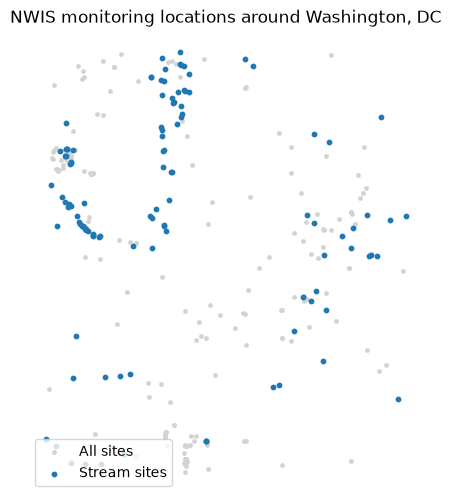

In [6]:
ax = frame.plot(color="lightgray", markersize=6, figsize=(6, 6), label="All sites")
gpd.GeoDataFrame.from_arrow(streams.to_arrow()).plot(
    ax=ax, color="tab:blue", markersize=10, label="Stream sites"
)
ax.legend(loc="lower left")
ax.set(title="NWIS monitoring locations around Washington, DC")
ax.set_axis_off()

## Daily discharge, split by year

`split_datetime="year"` splits the interval into one piece a year and runs the pieces
concurrently, as USGS's efficiency guidance recommends. Parameter `00060` is discharge
and statistic `00003` the daily mean.

In [7]:
daily = nwis.collect(
    "daily",
    params={
        "monitoring_location_id": "USGS-01646500",
        "parameter_code": "00060",
        "statistic_id": "00003",
        "datetime": "2021-01-01/2025-12-31",
    },
    split_datetime="year",
)
print(len(daily.geojson["features"]), "days in", daily.pagination.page_count, "pages")
print(daily.pagination.completeness, daily.pagination.checks)

1826 days in 5 pages
complete ('end_of_links', 'unique_ids')


polars reads the same table. The pieces arrive in the order they finish, so sort by
date before plotting.

In [8]:
import polars as pl

values = (
    pl.from_arrow(daily.to_arrow())
    .select(pl.col("time").str.to_date(), pl.col("value").cast(pl.Float64))
    .sort("time")
)
values.head()

time,value
date,f64
2021-01-01,16900.0
2021-01-02,23400.0
2021-01-03,25700.0
2021-01-04,31900.0
2021-01-05,31500.0


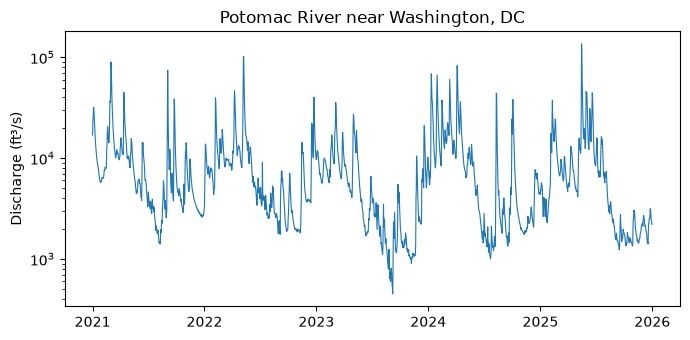

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(values["time"], values["value"], linewidth=0.8)
ax.set(yscale="log", ylabel="Discharge (ft³/s)", title="Potomac River near Washington, DC")
fig.tight_layout()

In [10]:
nwis.close()